In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully


In [3]:
df = pd.read_csv("../Dataset/SuperStoreOrders.csv")

df.head()


FileNotFoundError: [Errno 2] No such file or directory: '../Dataset/SuperStoreOrders.csv'

In [4]:
import os

print(os.getcwd())
print(os.listdir("../"))
print(os.listdir("../Dataset"))


/Users/desavinay/Desktop/ Qskill_retail_sales_analysis/Notebook
['Visualization', '.DS_Store', 'Dataset', 'Readme', 'Notebook']
['Qskillsuperstore.csv']


In [5]:
df = pd.read_csv("../Dataset/Qskillsuperstore.csv")
df.head()

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [6]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape:
(51290, 21)

Column Names:
['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name', 'segment', 'state', 'country', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority', 'year']


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51290 non-null  str    
 1   order_date      51290 non-null  str    
 2   ship_date       51290 non-null  str    
 3   ship_mode       51290 non-null  str    
 4   customer_name   51290 non-null  str    
 5   segment         51290 non-null  str    
 6   state           51290 non-null  str    
 7   country         51290 non-null  str    
 8   market          51290 non-null  str    
 9   region          51290 non-null  str    
 10  product_id      51290 non-null  str    
 11  category        51290 non-null  str    
 12  sub_category    51290 non-null  str    
 13  product_name    51290 non-null  str    
 14  sales           51290 non-null  str    
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit          51290 non-null  float64
 1

In [8]:
df.isnull().sum()

order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_name     0
segment           0
state             0
country           0
market            0
region            0
product_id        0
category          0
sub_category      0
product_name      0
sales             0
quantity          0
discount          0
profit            0
shipping_cost     0
order_priority    0
year              0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
df.describe()

,quantity,discount,profit,shipping_cost,year
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,3.476545,0.142908,28.641740,26.375915,2012.777208
std,2.278766,0.212280,174.424113,57.296804,1.098931
min,1.000000,0.000000,-6599.978000,0.000000,2011.000000
25%,2.000000,0.000000,0.000000,2.610000,2012.000000
50%,3.000000,0.000000,9.240000,7.790000,2013.000000
75%,5.000000,0.200000,36.810000,24.450000,2014.000000
max,14.000000,0.850000,8399.976000,933.570000,2014.000000


In [11]:
clean_df = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", clean_df.shape)

Original shape: (51290, 21)
Working copy shape: (51290, 21)


In [12]:
text_columns = clean_df.select_dtypes(include="object").columns

for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()

print("Text columns cleaned successfully")

Text columns cleaned successfully


/var/folders/4w/6gp6gmg50_5fczzk0p7f3qpw0000gn/T/ipykernel_6721/3462333198.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = clean_df.select_dtypes(include="object").columns


In [13]:
clean_df["order_date"] = pd.to_datetime(
    clean_df["order_date"],
    errors="coerce"
)

clean_df["ship_date"] = pd.to_datetime(
    clean_df["ship_date"],
    errors="coerce"
)

print(clean_df[["order_date", "ship_date"]].dtypes)

order_date    datetime64[us]
ship_date     datetime64[us]
dtype: object


In [14]:
clean_df["sales"] = pd.to_numeric(
    clean_df["sales"].astype(str).str.replace(",", ""),
    errors="coerce"
)

print("Sales data type:", clean_df["sales"].dtype)

Sales data type: int64


In [15]:
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

Missing values after cleaning:
order_id              0
order_date        31223
ship_date         31456
ship_mode             0
customer_name         0
segment               0
state                 0
country               0
market                0
region                0
product_id            0
category              0
sub_category          0
product_name          0
sales                 0
quantity              0
discount              0
profit                0
shipping_cost         0
order_priority        0
year                  0
dtype: int64


In [16]:
print("Original order_date examples:")
print(df["order_date"].head(20).to_list())

print("\nOriginal ship_date examples:")
print(df["ship_date"].head(20).to_list())

Original order_date examples:
['1/1/2011', '1/1/2011', '1/1/2011', '1/1/2011', '1/1/2011', '1/1/2011', '2/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011', '3/1/2011']

Original ship_date examples:
['6/1/2011', '8/1/2011', '5/1/2011', '5/1/2011', '8/1/2011', '8/1/2011', '6/1/2011', '3/1/2011', '9/1/2011', '7/1/2011', '7/1/2011', '7/1/2011', '7/1/2011', '9/1/2011', '9/1/2011', '7/1/2011', '7/1/2011', '9/1/2011', '9/1/2011', '8/1/2011']


In [17]:
clean_df["order_date"] = pd.to_datetime(
    df["order_date"],
    format="%m/%d/%Y",
    errors="coerce"
)

clean_df["ship_date"] = pd.to_datetime(
    df["ship_date"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("Order date type:", clean_df["order_date"].dtype)
print("Ship date type:", clean_df["ship_date"].dtype)

Order date type: datetime64[us]
Ship date type: datetime64[us]


In [18]:
print("Missing order dates:", clean_df["order_date"].isnull().sum())
print("Missing ship dates:", clean_df["ship_date"].isnull().sum())

Missing order dates: 31223
Missing ship dates: 31456


In [19]:
failed_order_dates = df.loc[
    clean_df["order_date"].isna(),
    "order_date"
]

print("Number of failed order dates:", len(failed_order_dates))
print("\nExamples:")
print(failed_order_dates.head(30).to_list())

Number of failed order dates: 31223

Examples:
['13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011', '14-01-2011']


In [20]:
failed_ship_dates = df.loc[
    clean_df["ship_date"].isna(),
    "ship_date"
]

print("Number of failed ship dates:", len(failed_ship_dates))
print("\nExamples:")
print(failed_ship_dates.head(30).to_list())

Number of failed ship dates: 31456

Examples:
['13-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '14-01-2011', '13-01-2011', '13-01-2011', '13-01-2011', '14-01-2011', '13-01-2011', '13-01-2011', '14-01-2011', '13-01-2011', '14-01-2011', '13-01-2011', '14-01-2011', '13-01-2011', '14-01-2011', '15-01-2011', '16-01-2011', '14-01-2011', '15-01-2011', '14-01-2011', '14-01-2011', '15-01-2011', '15-01-2011', '14-01-2011', '18-01-2011', '16-01-2011', '18-01-2011']


In [21]:
def parse_mixed_date(series):
    result = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")

    slash_format = series.str.contains("/", na=False)
    hyphen_format = series.str.contains("-", na=False)

    result.loc[slash_format] = pd.to_datetime(
        series.loc[slash_format],
        format="%m/%d/%Y",
        errors="coerce"
    )

    result.loc[hyphen_format] = pd.to_datetime(
        series.loc[hyphen_format],
        format="%d-%m-%Y",
        errors="coerce"
    )

    return result


clean_df["order_date"] = parse_mixed_date(df["order_date"])
clean_df["ship_date"] = parse_mixed_date(df["ship_date"])

print("Order date type:", clean_df["order_date"].dtype)
print("Ship date type:", clean_df["ship_date"].dtype)

Order date type: datetime64[ns]
Ship date type: datetime64[ns]


In [22]:
print("Missing order dates:", clean_df["order_date"].isnull().sum())
print("Missing ship dates:", clean_df["ship_date"].isnull().sum())

Missing order dates: 0
Missing ship dates: 0


In [23]:
print("Duplicate rows:", clean_df.duplicated().sum())

Duplicate rows: 0


In [24]:
clean_df.shape

(51290, 21)

In [25]:
print("Total Sales:", clean_df["sales"].sum())
print("Total Profit:", clean_df["profit"].sum())
print("Total Quantity Sold:", clean_df["quantity"].sum())

Total Sales: 12642905
Total Profit: 1469034.82128
Total Quantity Sold: 178312


In [26]:
print("Unique Customers:", clean_df["customer_name"].nunique())

Unique Customers: 795


In [27]:
top_customers_sales = (
    clean_df.groupby("customer_name")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers_sales)

customer_name
Tom Ashbrook          40489
Tamara Chand          37453
Greg Tran             35552
Christopher Conant    35187
Sean Miller           35170
Bart Watters          32315
Natalie Fritzler      31778
Fred Hopkins          30404
Jane Waco             30288
Hunter Lopez          30246
Name: sales, dtype: int64


In [28]:
top_customers_profit = (
    clean_df.groupby("customer_name")["profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers_profit)

customer_name
Tamara Chand       8672.89890
Raymond Buch       8453.04950
Sanjit Chand       8205.37990
Hunter Lopez       7816.56778
Bill Eplett        7410.00530
Harry Marie        6958.28640
Susan Pistek       6484.40726
Mike Gockenbach    6458.67620
Adrian Barton      6417.28450
Tom Ashbrook       6311.97910
Name: profit, dtype: float64


In [29]:
category_sales = (
    clean_df.groupby("category")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

category
Technology         4744691
Furniture          4110884
Office Supplies    3787330
Name: sales, dtype: int64


In [30]:
category_profit = (
    clean_df.groupby("category")["profit"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)

category
Technology         663778.73318
Office Supplies    518473.83430
Furniture          286782.25380
Name: profit, dtype: float64


In [31]:
category_quantity = (
    clean_df.groupby("category")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(category_quantity)

category
Office Supplies    108182
Technology          35176
Furniture           34954
Name: quantity, dtype: int64


In [32]:
subcategory_sales = (
    clean_df.groupby("sub_category")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(subcategory_sales)

sub_category
Phones         1706874
Copiers        1509439
Chairs         1501682
Bookcases      1466559
Storage        1127124
Appliances     1011081
Machines        779071
Tables          757034
Accessories     749307
Binders         461952
Furnishings     385609
Art             372163
Paper           244307
Supplies        243090
Envelopes       170926
Fasteners        83254
Labels           73433
Name: sales, dtype: int64


In [33]:
subcategory_profit = (
    clean_df.groupby("sub_category")["profit"]
    .sum()
    .sort_values(ascending=False)
)

print(subcategory_profit)

sub_category
Copiers        258567.54818
Phones         216717.00580
Bookcases      161924.41950
Chairs         141973.79750
Appliances     141680.58940
Accessories    129626.30620
Storage        108461.48980
Binders         72449.84600
Paper           59207.68270
Machines        58867.87300
Art             57953.91090
Furnishings     46967.42550
Envelopes       29601.11630
Supplies        22583.26310
Labels          15010.51200
Fasteners       11525.42410
Tables         -64083.38870
Name: profit, dtype: float64


In [34]:
region_sales = (
    clean_df.groupby("region")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

region
Central           2822399
South             1600960
North             1248192
Oceania           1100207
Southeast Asia     884438
North Asia         848349
EMEA               806184
Africa             783776
Central Asia       752839
West               725514
East               678834
Caribbean          324281
Canada              66932
Name: sales, dtype: int64


In [35]:
region_profit = (
    clean_df.groupby("region")["profit"]
    .sum()
    .sort_values(ascending=False)
)

print(region_profit)

region
Central           311403.98164
North             194597.95252
North Asia        165578.42100
South             140355.76618
Central Asia      132480.18700
Oceania           121666.64200
West              108418.44890
East               91522.78000
Africa             88871.63100
EMEA               43897.97100
Caribbean          34571.32104
Southeast Asia     17852.32900
Canada             17817.39000
Name: profit, dtype: float64


In [36]:
region_quantity = (
    clean_df.groupby("region")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(region_quantity)

region
Central           41762
South             25206
North             18021
Oceania           12838
West              12266
Southeast Asia    11822
EMEA              11517
East              10618
Africa            10564
North Asia         8851
Central Asia       7715
Caribbean          6299
Canada              833
Name: quantity, dtype: int64


In [37]:
yearly_sales = (
    clean_df.groupby("year")["sales"]
    .sum()
    .sort_index()
)

print(yearly_sales)

year
2011    2259511
2012    2677493
2013    3405860
2014    4300041
Name: sales, dtype: int64


In [38]:
yearly_profit = (
    clean_df.groupby("year")["profit"]
    .sum()
    .sort_index()
)

print(yearly_profit)

year
2011    248940.81154
2012    307415.27910
2013    408512.76018
2014    504165.97046
Name: profit, dtype: float64


In [39]:
yearly_quantity = (
    clean_df.groupby("year")["quantity"]
    .sum()
    .sort_index()
)

print(yearly_quantity)

year
2011    31443
2012    38111
2013    48136
2014    60622
Name: quantity, dtype: int64


In [40]:
monthly_sales = (
    clean_df.groupby(clean_df["order_date"].dt.to_period("M"))["sales"]
    .sum()
)

print(monthly_sales)

order_date
2011-01    138245
2011-02    134969
2011-03    171445
2011-04    128843
2011-05    148158
2011-06    189339
2011-07    162039
2011-08    219236
2011-09    255250
2011-10    204679
2011-11    214931
2011-12    292377
2012-01    162807
2012-02    152663
2012-03    201626
2012-04    187470
2012-05    218953
2012-06    249284
2012-07    174403
2012-08    271675
2012-09    256592
2012-10    239324
2012-11    270725
2012-12    291971
2013-01    206467
2013-02    191077
2013-03    230551
2013-04    233188
2013-05    304523
2013-06    341161
2013-07    223649
2013-08    323889
2013-09    326904
2013-10    270131
2013-11    383051
2013-12    371269
2014-01    268275
2014-02    244179
2014-03    347757
2014-04    302140
2014-05    304795
2014-06    372608
2014-07    278670
2014-08    432742
2014-09    405455
2014-10    406676
2014-11    508985
2014-12    427759
Freq: M, Name: sales, dtype: int64


In [41]:
monthly_profit = (
    clean_df.groupby(clean_df["order_date"].dt.to_period("M"))["profit"]
    .sum()
)

print(monthly_profit)

order_date
2011-01    13457.23302
2011-02    17588.83726
2011-03    16169.36062
2011-04    13405.46924
2011-05    14777.45792
2011-06    25932.87796
2011-07    10631.84406
2011-08    19650.67124
2011-09    32313.25458
2011-10    30745.54166
2011-11    21261.40536
2011-12    33006.85862
2012-01    19627.42058
2012-02    17828.18244
2012-03    22752.87684
2012-04    20804.00532
2012-05    22865.39572
2012-06    34358.03962
2012-07    21725.18808
2012-08    36511.44996
2012-09    25039.93498
2012-10    27773.87454
2012-11    26160.60686
2012-12    31968.30416
2013-01    26052.40252
2013-02    31553.99756
2013-03    34873.71938
2013-04    26008.05144
2013-05    40630.83946
2013-06    43298.85000
2013-07    27019.91294
2013-08    32977.75576
2013-09    18850.09084
2013-10    27871.97470
2013-11    51720.88568
2013-12    47654.27990
2014-01    31447.74660
2014-02    29454.01876
2014-03    50097.04458
2014-04    35709.53320
2014-05    34335.60404
2014-06    40869.02108
2014-07    26450.70856


In [42]:
monthly_quantity = (
    clean_df.groupby(clean_df["order_date"].dt.to_period("M"))["quantity"]
    .sum()
)

print(monthly_quantity)

order_date
2011-01    2178
2011-02    1794
2011-03    2183
2011-04    2181
2011-05    2057
2011-06    2715
2011-07    2266
2011-08    2909
2011-09    3357
2011-10    2615
2011-11    3165
2011-12    4023
2012-01    2150
2012-02    2156
2012-03    2880
2012-04    2506
2012-05    3239
2012-06    3508
2012-07    2551
2012-08    3451
2012-09    3752
2012-10    3399
2012-11    4497
2012-12    4022
2013-01    2766
2013-02    2535
2013-03    3130
2013-04    3161
2013-05    4115
2013-06    4948
2013-07    3594
2013-08    4564
2013-09    5067
2013-10    3977
2013-11    5274
2013-12    5005
2014-01    3656
2014-02    3450
2014-03    4820
2014-04    4397
2014-05    4415
2014-06    5528
2014-07    3867
2014-08    5506
2014-09    5741
2014-10    5915
2014-11    7020
2014-12    6307
Freq: M, Name: quantity, dtype: int64


In [43]:
top_products_sales = (
    clean_df.groupby("product_name")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_sales)

product_name
Apple Smart Phone, Full Size                                86936
Cisco Smart Phone, Full Size                                76441
Motorola Smart Phone, Full Size                             73159
Nokia Smart Phone, Full Size                                71904
Canon imageCLASS 2200 Advanced Copier                       61600
Hon Executive Leather Armchair, Adjustable                  58200
Office Star Executive Leather Armchair, Adjustable          50667
Harbour Creations Executive Leather Armchair, Adjustable    50120
Samsung Smart Phone, Cordless                               48654
Nokia Smart Phone, with Caller ID                           47880
Name: sales, dtype: int64


In [44]:
top_products_profit = (
    clean_df.groupby("product_name")["profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_profit)

product_name
Canon imageCLASS 2200 Advanced Copier                       25199.9280
Cisco Smart Phone, Full Size                                17238.5206
Motorola Smart Phone, Full Size                             17027.1130
Hoover Stove, Red                                           11807.9690
Sauder Classic Bookcase, Traditional                        10672.0730
Harbour Creations Executive Leather Armchair, Adjustable    10427.3260
Nokia Smart Phone, Full Size                                 9938.1955
Cisco Smart Phone, with Caller ID                            9786.6408
Nokia Smart Phone, with Caller ID                            9465.3257
Belkin Router, USB                                           8955.0180
Name: profit, dtype: float64


In [45]:
segment_sales = (
    clean_df.groupby("segment")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(segment_sales)

segment
Consumer       6508141
Corporate      3824808
Home Office    2309956
Name: sales, dtype: int64


In [46]:
segment_profit = (
    clean_df.groupby("segment")["profit"]
    .sum()
    .sort_values(ascending=False)
)

print(segment_profit)

segment
Consumer       749239.78206
Corporate      442785.85866
Home Office    277009.18056
Name: profit, dtype: float64


In [47]:
segment_quantity = (
    clean_df.groupby("segment")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(segment_quantity)

segment
Consumer       92157
Corporate      53565
Home Office    32590
Name: quantity, dtype: int64


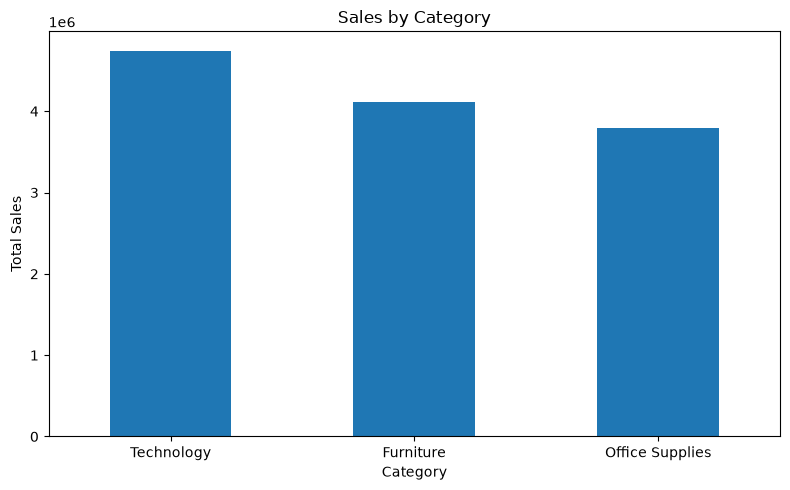

In [48]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

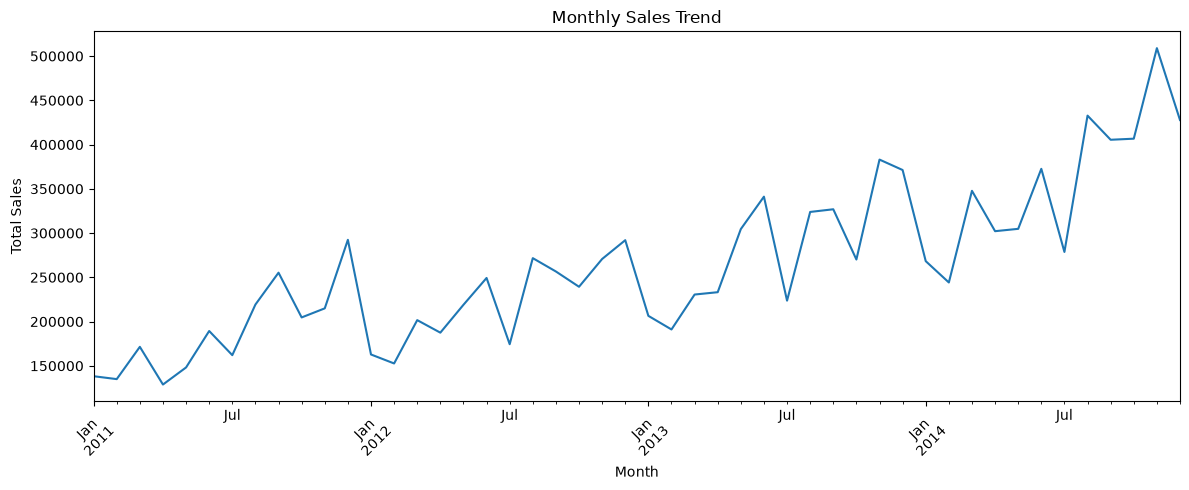

In [49]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

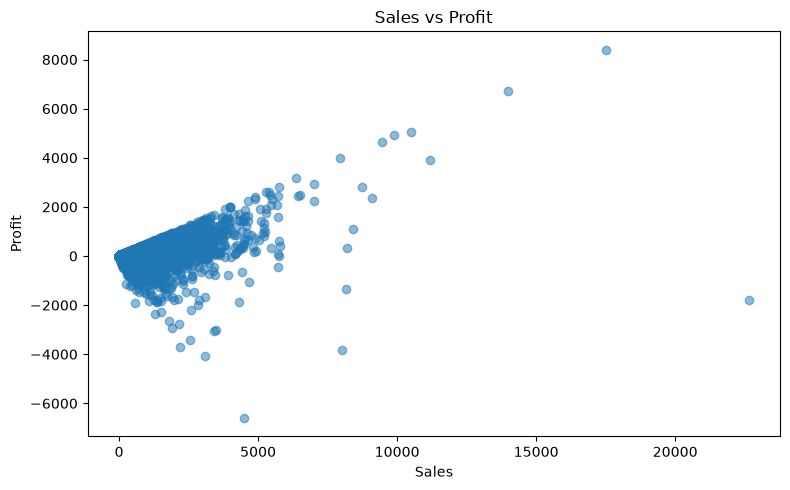

In [50]:
plt.figure(figsize=(8, 5))

plt.scatter(clean_df["sales"], clean_df["profit"], alpha=0.5)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()

plt.show()

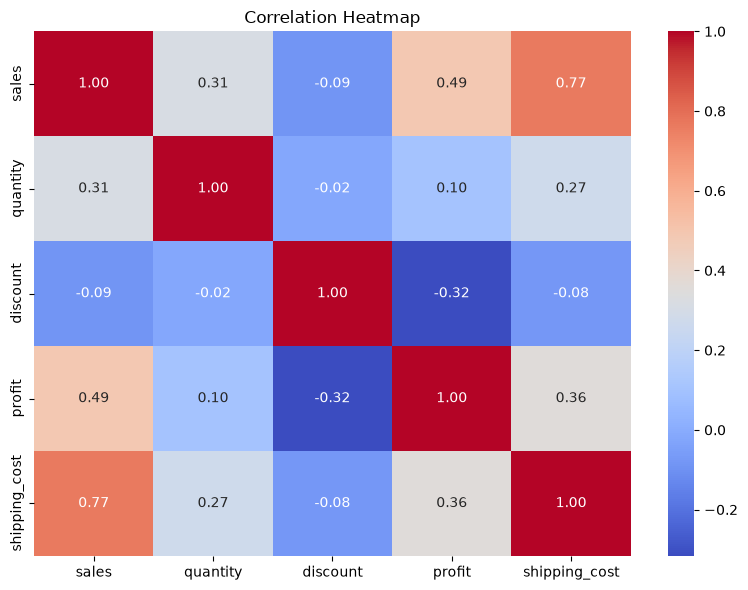

In [51]:
plt.figure(figsize=(8, 6))

numeric_columns = clean_df[
    ["sales", "quantity", "discount", "profit", "shipping_cost"]
]

correlation = numeric_columns.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.show()

## Business Insights & Observations

### 1. Category Performance
- Technology generated the highest total sales and profit among the three categories.
- Furniture generated the second-highest sales but its profit was lower compared with Technology.
- Office Supplies had the highest quantity sold, showing strong sales volume despite lower total sales.
- This shows that higher quantity or sales volume does not always result in the highest profit.

### 2. Product and Sub-Category Performance
- Phones generated the highest sales among the sub-categories.
- Copiers generated the highest profit among the sub-categories.
- Tables recorded a negative overall profit, indicating that this sub-category generated losses.
- The highest-selling products were not always the most profitable products.

### 3. Customer Performance
- The dataset contains 795 unique customers.
- The top customers contributed significantly to overall sales and profit.
- The customer with the highest sales was not the same customer with the highest profit.
- This indicates that customer value should be evaluated using both revenue and profitability.

### 4. Regional Performance
- The Central region recorded the highest sales, profit, and quantity.
- Regional performance varies considerably across the dataset.
- Lower-performing regions may require further analysis of products, customers, and sales strategies.

### 5. Customer Segment Performance
- The Consumer segment generated the highest sales, profit, and quantity.
- Corporate was the second-highest-performing segment.
- Home Office recorded the lowest sales, profit, and quantity among the three segments.

### 6. Sales Trend
- Monthly sales show an overall upward trend from 2011 to 2014.
- Sales fluctuate considerably from month to month.
- The highest monthly sales occurred near the end of 2014.
- This indicates long-term growth along with monthly variations.

### 7. Sales and Profit Relationship
- The scatter plot shows a general positive relationship between sales and profit.
- However, several transactions have positive sales but negative profit.
- Therefore, increasing sales alone does not guarantee profitability.

### 8. Discount and Profit
- The correlation between discount and profit is -0.32.
- This indicates a moderate negative relationship between discount and profit in this dataset.
- Higher discounts are generally associated with lower profit.

### 9. Overall Business Observation
- Technology is a major contributor to both sales and profitability.
- Some high-volume products or categories do not necessarily generate the highest profit.
- Monitoring discounts, loss-making products, customer profitability, and regional performance can help identify areas for improvement.

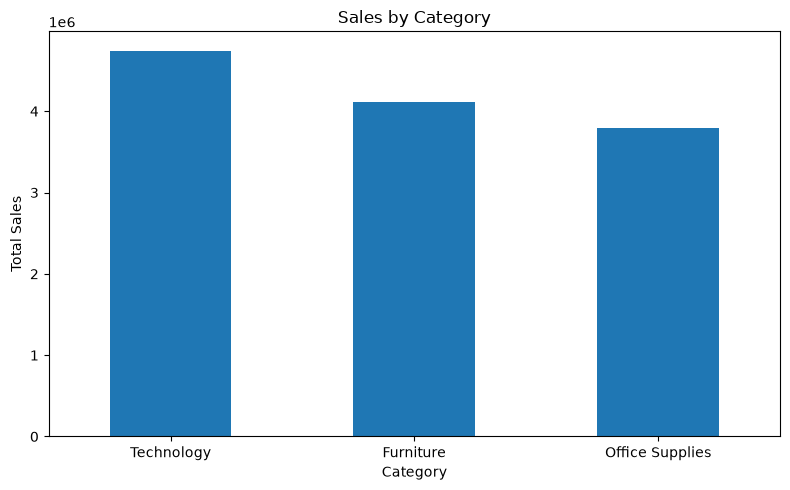

In [52]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualization/sales_by_category.png", dpi=300, bbox_inches="tight")

plt.show()

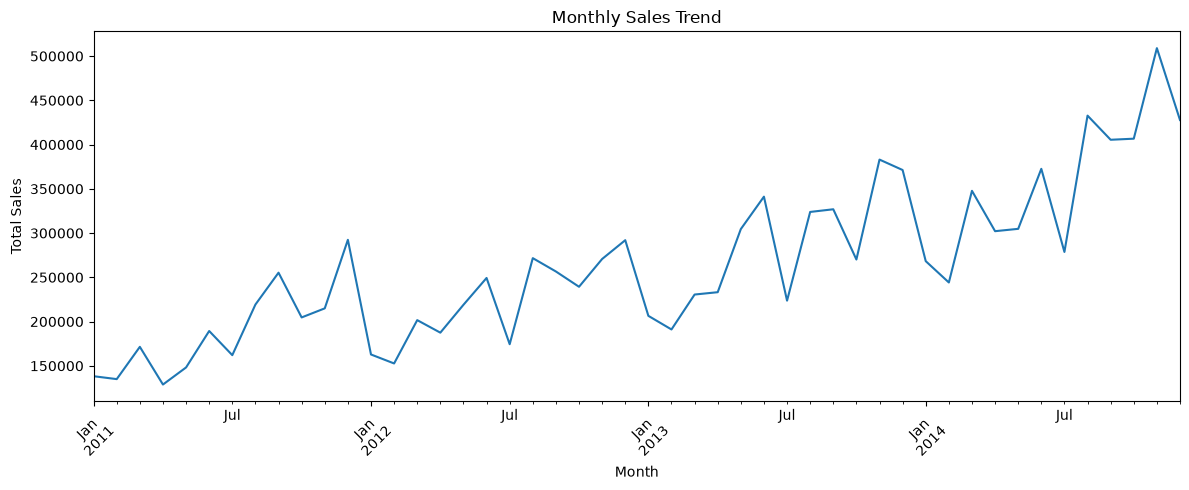

In [53]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../Visualization/monthly_sales_trend.png", dpi=300, bbox_inches="tight")

plt.show()

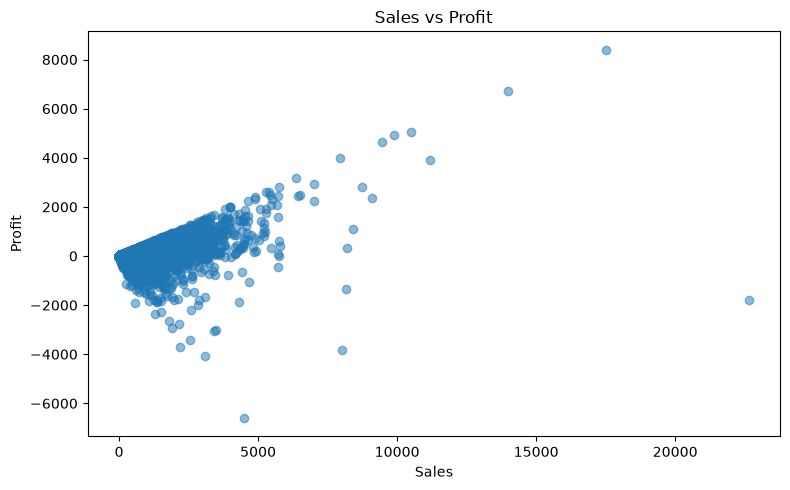

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(clean_df["sales"], clean_df["profit"], alpha=0.5)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()

plt.savefig("../Visualization/sales_vs_profit.png", dpi=300, bbox_inches="tight")

plt.show()

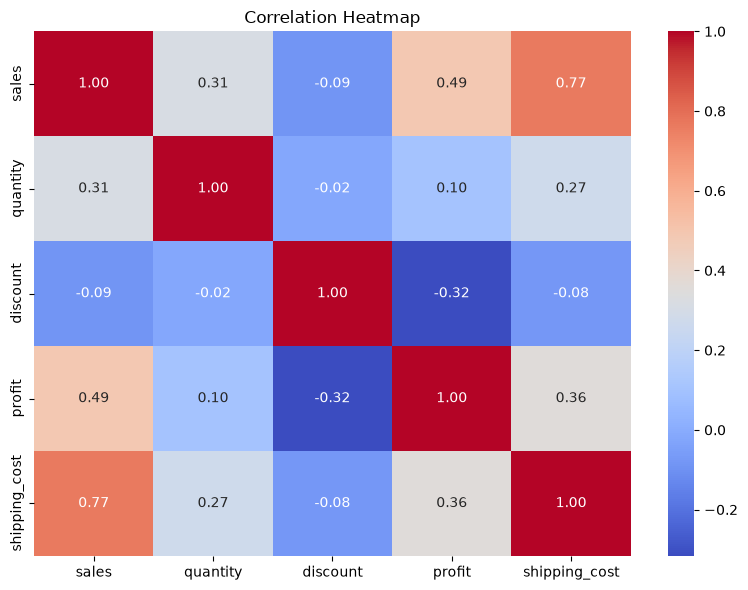

In [55]:
plt.figure(figsize=(8, 6))

numeric_columns = clean_df[
    ["sales", "quantity", "discount", "profit", "shipping_cost"]
]

correlation = numeric_columns.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../Visualization/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

In [56]:
yearly_analysis = clean_df.groupby(clean_df["order_date"].dt.year).agg(
    Sales=("sales", "sum"),
    Profit=("profit", "sum"),
    Quantity=("quantity", "sum")
)

yearly_analysis

,Sales,Profit,Quantity
order_date,,,
2011,2259511,248940.81154,31443
2012,2677493,307415.27910,38111
2013,3405860,408512.76018,48136
2014,4300041,504165.97046,60622
